# Neural permutation selector for Dumer decoding of RM(3,9)  (n=512)

The RM encoder and the Dumer recursive decoder are **not modified**. Two things are added in front of Dumer:

1. a classical check-node front-end that refines the channel LLRs (set `USE_FRONTEND = False` to switch it off);
2. a **neural selector**: RM codes are invariant under affine coordinate permutations, which change how Dumer groups
   (box-plus combines) the received symbols. The network scores `P_PERMS` candidate permutations from cheap first-leaf
   features and the best one is fed to **one** full Dumer decode.

Rows reported: plain Dumer, front-end + Dumer, front-end + hand-written selector (non-neural reference),
front-end + NN selector, front-end + NN top-2 (two decodes). BLER of plain Dumer goes from 0.27 (-3 dB) to ~4e-5 (-0.5 dB).

`MODE = "compute_and_save"` trains and evaluates; `MODE = "analyze_only"` re-plots a previous run.
Everything you may want to change is in **Cell 2**.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"  # Select GPU index (project rule: GPU 1 only)

import sys, math, time, json, random
from math import comb
from pathlib import Path
from datetime import datetime
import numpy as np
import scipy.io as sio
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

PyTorch: 2.5.1
CUDA Available: True


In [2]:
# ========================================
# ALL PARAMETERS & CONFIGURATION
# ========================================
MODE = "compute_and_save"        # "compute_and_save" | "analyze_only"
ANALYZE_RUN_DIR = ""             # used only when MODE == "analyze_only" (path to a run directory)

PROJECT_NAME = "HiKO_PermSel"
DATASET_NAME = "awgn_bpsk"
MODEL_NAME = "nn_permutation_selector"

# --- Code: RM(R, M); n = 2^M ---
R = 3
M = 9

# --- Classical front-end (not trained; set USE_FRONTEND = False to remove it) ---
USE_FRONTEND = True
DV = 128                         # checks per code bit
T_ROUNDS = 2                     # message-passing rounds
ALPHA_INIT = 0.4                 # check-message gain

# --- Permutation candidates ---
P_PERMS = 16                     # number of candidate affine permutations (identity included)
PERM_SEED = 1

# --- Selector training ---
TRAIN_SNRS = [-2.5, -2.0]          # frames where Dumer+front-end fails often enough to be informative
TRAIN_FRAMES = 1000000             # total generated frames (only the informative ones are kept)
SELECTOR_HIDDEN = 128
EPOCHS = 120
LEARNING_RATE = 1e-3

# --- Final waterfall evaluation ---
EVAL_SNRS = [-3.0, -2.5, -2.0, -1.5, -1.0, -0.5]
MIN_BLOCK_ERRORS = 400           # stop an SNR point (per method) after this many block errors ...
MAX_WORDS = 10_000_000            # ... or this many codewords
BATCH = 1000                    # frames per GPU batch (lower it if you run out of GPU memory)
COMPUTE_ORACLE = False           # True: also report the best-of-P oracle (needs P full decodes per frame, slow)

# --- Analysis for the paper ---
RUN_ANALYSIS = True              # error-nature / selector-behaviour / ablation / cost tables
ANALYSIS_SNRS = [-2.0, -1.5]      # SNRs (inside the waterfall) at which the diagnostics are measured
ANALYSIS_WORDS = 60000           # frames per analysis SNR
BLER_TARGETS = [1e-2, 1e-3, 1e-4]   # for the "SNR needed / dB gain" table

SEED = 42
NUM_GPUS = torch.cuda.device_count()
PLOT_DPI = 300

print("=" * 70)
print("CONFIGURATION")
print("=" * 70)
for k in ["MODE", "R", "M", "USE_FRONTEND", "DV", "T_ROUNDS", "ALPHA_INIT", "P_PERMS", "TRAIN_SNRS", "TRAIN_FRAMES",
          "EPOCHS", "EVAL_SNRS", "MIN_BLOCK_ERRORS", "MAX_WORDS", "BATCH", "ANALYSIS_SNRS", "SEED"]:
    print(f"{k}: {globals()[k]}")
print(f"Available GPUs (visible): {NUM_GPUS}")
print("=" * 70)

CONFIGURATION
MODE: compute_and_save
R: 3
M: 9
USE_FRONTEND: True
DV: 128
T_ROUNDS: 2
ALPHA_INIT: 0.4
P_PERMS: 16
TRAIN_SNRS: [-2.5, -2.0]
TRAIN_FRAMES: 1000000
EPOCHS: 120
EVAL_SNRS: [-3.0, -2.5, -2.0, -1.5, -1.0, -0.5]
MIN_BLOCK_ERRORS: 400
MAX_WORDS: 10000000
BATCH: 1000
ANALYSIS_SNRS: [-2.0, -1.5]
SEED: 42
Available GPUs (visible): 1


In [3]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    print(f"✓ Seeds set to {seed}")

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

✓ Seeds set to 42


In [4]:
# ========================================
# AUTO DIRECTORY SETUP (name built from the Cell-2 parameters)
# ========================================
def generate_run_name_from_config():
    p = {'r': R, 'm': M, 'fe': int(USE_FRONTEND), 'dv': DV, 'T': T_ROUNDS, 'a': f"{ALPHA_INIT:.2f}".replace('.', ''),
         'P': P_PERMS, 'frames': TRAIN_FRAMES, 'ep': EPOCHS, 'seed': SEED}
    return PROJECT_NAME + "_" + "_".join(f"{k}{v}" for k, v in p.items()) + "_" + datetime.now().strftime("%Y%m%d_%H%M%S")

if MODE == "analyze_only":
    RESULTS_BASE_DIR = Path(ANALYZE_RUN_DIR); RUN_NAME = RESULTS_BASE_DIR.name
else:
    RUN_NAME = generate_run_name_from_config()
    RESULTS_BASE_DIR = Path("ResultsAndWeights") / RUN_NAME
RESULTS_DIR = RESULTS_BASE_DIR / "results_data"
WEIGHTS_DIR = RESULTS_BASE_DIR / "weights"
if MODE == "compute_and_save":
    RESULTS_DIR.mkdir(parents=True, exist_ok=True); WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("DIRECTORY SETUP")
print("=" * 70)
print(f"Run Name: {RUN_NAME}")
print(f"Results Base: {RESULTS_BASE_DIR.absolute()}")
print("=" * 70)

DIRECTORY SETUP
Run Name: HiKO_PermSel_r3_m9_fe1_dv128_T2_a040_P16_frames1000000_ep120_seed42_20261011_185517
Results Base: /DATA/shubham19/Documents/python_directory/higher_rate_kocodes/General-Rate-KO-Codes/selector_notebooks/ResultsAndWeights/HiKO_PermSel_r3_m9_fe1_dv128_T2_a040_P16_frames1000000_ep120_seed42_20261011_185517


In [5]:
# ========================================
# UTILITY FUNCTIONS
# ========================================
CONFIG_VARS = ['MODE', 'PROJECT_NAME', 'R', 'M', 'USE_FRONTEND', 'DV', 'T_ROUNDS', 'ALPHA_INIT', 'P_PERMS', 'PERM_SEED',
               'TRAIN_SNRS', 'TRAIN_FRAMES', 'SELECTOR_HIDDEN', 'EPOCHS', 'LEARNING_RATE', 'EVAL_SNRS',
               'MIN_BLOCK_ERRORS', 'MAX_WORDS', 'BATCH', 'COMPUTE_ORACLE', 'RUN_ANALYSIS', 'ANALYSIS_SNRS', 'ANALYSIS_WORDS', 'BLER_TARGETS', 'SEED']

def save_checkpoint(model, epoch, metric, filepath, is_best=False):
    torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(), 'metric': metric,
                'config': {k: globals()[k] for k in CONFIG_VARS if k in globals()}}, filepath)
    print(f"  ✓ Checkpoint saved: {Path(filepath).name}{' (BEST)' if is_best else ''}")

def save_results(metrics_dict, results_text, results_dir):
    sio.savemat(results_dir / "results_metrics.mat", metrics_dict)
    print(f"✓ Metrics saved (MATLAB .mat): {results_dir / 'results_metrics.mat'}")
    with open(results_dir / "results_summary.txt", 'w') as f:
        f.write(results_text)
    print(f"✓ Results saved (text format): {results_dir / 'results_summary.txt'}")

def log_all_config(base_dir):
    cfg = {k: globals()[k] for k in CONFIG_VARS if k in globals()}
    cfg.update(timestamp=datetime.now().isoformat(), cuda_available=torch.cuda.is_available(), device_count=torch.cuda.device_count())
    with open(base_dir / "config.json", 'w') as f:
        json.dump(cfg, f, indent=2)
    print(f"✓ Configuration saved: {base_dir / 'config.json'}")

## Classical backbone: RM encoder + Dumer decoder (unchanged)
`NeuralRM(r, m)` with default arguments is plain RM Plotkin encoding and Dumer recursive decoding (exact box-plus, bitwise-MAP first-order leaves via the fast Hadamard transform, hard feedback).

In [6]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from math import comb


def rm_dim(r, m):
    r = min(r, m)
    return sum(comb(m, i) for i in range(r + 1)) if r >= 0 else 0


def snr_db2sigma(snr_db):
    # Es/N0 convention, same as the existing KO / HiKO code
    return 10 ** (-snr_db / 20) / math.sqrt(2)


# ------------------------------------------------------------------ FHT
def fht(x):
    """Sylvester Hadamard transform along last dim (natural order)."""
    n = x.shape[-1]
    shp = x.shape[:-1]
    h = 1
    while h < n:
        x = x.reshape(*shp, n // (2 * h), 2, h)
        a, b = x[..., 0, :], x[..., 1, :]
        x = torch.stack((a + b, a - b), dim=-2).reshape(*shp, n)
        h *= 2
    return x


def first_order_encode(msg, m):
    """msg (B, m+1) +/-1 -> codeword (B, 2^m): x_j = s0 * prod_i s_i^{bit_i(j)}"""
    n = 2 ** m
    j = torch.arange(n, device=msg.device)
    x = msg[:, :1].expand(-1, n).clone()
    for i in range(m):
        bit = ((j >> i) & 1).bool()
        x = torch.where(bit.unsqueeze(0), x * msg[:, 1 + i:2 + i], x)
    return x


def first_order_decode(L, m, exact=True):
    """Bitwise MAP (exact or max-log) for RM(1,m). Returns msg LLRs (B, m+1)."""
    B = L.shape[0]
    T = fht(L) * 0.5                      # metric of +H_a codeword is T[a]
    out = []
    if exact:
        S = torch.logaddexp(T, -T)        # log(e^T + e^-T)
        out.append(torch.logsumexp(T, 1) - torch.logsumexp(-T, 1))
        for i in range(m):
            Sv = S.reshape(B, 2 ** (m - 1 - i), 2, 2 ** i)
            out.append(torch.logsumexp(Sv[:, :, 0, :].reshape(B, -1), 1)
                       - torch.logsumexp(Sv[:, :, 1, :].reshape(B, -1), 1))
    else:
        S = T.abs()
        out.append(T.max(1)[0] + T.min(1)[0])
        for i in range(m):
            Sv = S.reshape(B, 2 ** (m - 1 - i), 2, 2 ** i)
            out.append(Sv[:, :, 0, :].reshape(B, -1).max(1)[0]
                       - Sv[:, :, 1, :].reshape(B, -1).max(1)[0])
    return torch.stack(out, 1)


def boxplus(a, b, exact=True):
    if exact:
        # 2 atanh(tanh(a/2) tanh(b/2)), numerically stable form
        return (torch.sign(a) * torch.sign(b) * torch.minimum(a.abs(), b.abs())
                + torch.log1p(torch.exp(-(a + b).abs())) - torch.log1p(torch.exp(-(a - b).abs())))
    return torch.sign(a) * torch.sign(b) * torch.minimum(a.abs(), b.abs())


# ------------------------------------------------------------------ NN blocks
class ResMLP(nn.Module):
    """Coordinate-wise MLP whose output is ADDED to a classical function.
    Last layer zero-initialised -> module starts exactly at classical."""

    def __init__(self, d_in, hidden=32, layers=3, d_out=1, act='selu'):
        super().__init__()
        dims = [d_in] + [hidden] * (layers - 1)
        self.hid = nn.ModuleList([nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:])])
        self.out = nn.Linear(dims[-1], d_out)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)
        self.act = {'selu': F.selu, 'elu': F.elu, 'gelu': F.gelu, 'tanh': torch.tanh}[act]

    def forward(self, x):
        for l in self.hid:
            x = self.act(l(x))
        return self.out(x)


# ------------------------------------------------------------------ code tree
class Node:
    def __init__(self, r, m, path):
        self.r, self.m, self.path = r, m, path
        self.n, self.k = 2 ** m, rm_dim(r, m)
        if r == 0 or r == 1:
            self.leaf = True
        else:
            self.leaf = False
            self.u = Node(min(r, m - 1), m - 1, path + 'u')
            self.v = Node(r - 1, m - 1, path + 'v')

    def internal(self):
        if self.leaf:
            return []
        return [self] + self.u.internal() + self.v.internal()


class NeuralRM(nn.Module):
    """
    enc_mode : 'rm' (fixed RM code) | 'neural' (KO-style learned g)
    dec_mode : 'dumer' (classical) | 'neural' (learned fv, fu)
    """

    def __init__(self, r, m, enc_mode='rm', dec_mode='dumer', hidden=32, layers=3,
                 exact=True, feedback='hard', g_min_m=1, f_min_m=1, act='selu',
                 fu_full=True):
        super().__init__()
        self.r, self.m = r, m
        self.root = Node(r, m, 'R')
        self.n, self.k = self.root.n, self.root.k
        self.enc_mode, self.dec_mode = enc_mode, dec_mode
        self.exact, self.feedback = exact, feedback
        self.fu_full = fu_full
        self.g = nn.ModuleDict()
        self.fv = nn.ModuleDict()
        self.fu = nn.ModuleDict()
        for nd in self.root.internal():
            if enc_mode == 'neural' and nd.m >= g_min_m:
                self.g[nd.path] = ResMLP(2, hidden, layers, act=act)
            if dec_mode == 'neural' and nd.m >= f_min_m:
                self.fv[nd.path] = ResMLP(4, hidden, layers, act=act)
                self.fu[nd.path] = ResMLP(5 if fu_full else 3, hidden, layers, act=act)

    # ---------------- encoder
    def _enc(self, msg, nd):
        if nd.leaf:
            if nd.r == 0:
                return msg.expand(-1, nd.n)
            return first_order_encode(msg, nd.m)
        ku = nd.u.k
        u = self._enc(msg[:, :ku], nd.u)
        v = self._enc(msg[:, ku:], nd.v)
        uv = u * v
        if nd.path in self.g:
            uv = uv + self.g[nd.path](torch.stack((u, v), -1)).squeeze(-1)
        return torch.cat((u, uv), 1)

    def encode(self, msg):
        x = self._enc(msg, self.root)
        if self.enc_mode == 'neural':
            x = F.normalize(x, p=2, dim=1) * math.sqrt(self.n)
        return x

    # ---------------- decoder
    def _fb(self, llr):
        """turn message LLRs into the feedback symbols used for re-encoding"""
        if self.feedback == 'hard':
            return torch.sign(llr)
        if self.feedback == 'ste':        # hard forward, soft gradient
            s = torch.tanh(llr / 2)
            return s + (torch.sign(llr) - s).detach()
        return torch.tanh(llr / 2)        # 'soft'

    def _dec(self, L, nd, genie_msg=None):
        """returns (msg_llr (B,k), x_hat (B,n) re-encoded estimate)"""
        if nd.leaf:
            if getattr(self, 'collect', None) is not None:
                self.collect.append((nd, L))
            if nd.r == 0:
                llr = L.sum(1, keepdim=True)
            else:
                llr = first_order_decode(L, nd.m, self.exact)
            fb = genie_msg if genie_msg is not None else self._fb(llr)
            return llr, self._enc(fb, nd)
        h = nd.n // 2
        L1, L2 = L[:, :h], L[:, h:]
        Lv = boxplus(L1, L2, self.exact)
        if nd.path in self.fv:
            feat = torch.stack((torch.asinh(L1) / 3, torch.asinh(L2) / 3, torch.tanh(L1 / 2), torch.tanh(L2 / 2)), -1)
            Lv = Lv + self.fv[nd.path](feat).squeeze(-1)
        ku = nd.u.k
        gv = genie_msg[:, ku:] if genie_msg is not None else None
        gu = genie_msg[:, :ku] if genie_msg is not None else None
        llr_v, v_hat = self._dec(Lv, nd.v, gv)
        Lu = L1 + v_hat * L2
        if nd.path in self.fu:
            if self.fu_full:
                feat = torch.stack((torch.asinh(L1) / 3, torch.asinh(L2) / 3, v_hat, torch.tanh(L1 / 2), torch.tanh(L2 / 2)), -1)
            else:
                feat = torch.stack((torch.asinh(L1) / 3, torch.asinh(L2) / 3, v_hat), -1)
            Lu = Lu + self.fu[nd.path](feat).squeeze(-1)
        llr_u, u_hat = self._dec(Lu, nd.u, gu)
        uv = u_hat * v_hat
        if nd.path in self.g:
            uv = uv + self.g[nd.path](torch.stack((u_hat, v_hat), -1)).squeeze(-1)
        return torch.cat((llr_u, llr_v), 1), torch.cat((u_hat, uv), 1)

    def decode(self, L, genie_msg=None):
        return self._dec(L, self.root, genie_msg)[0]

    def channel(self, x, snr_db):
        sigma = snr_db2sigma(snr_db)
        if torch.is_tensor(sigma):
            sigma = sigma.view(-1, 1)
        y = x + sigma * torch.randn_like(x)
        return 2 * y / sigma ** 2

    def forward(self, msg, snr_db, genie=False):
        x = self.encode(msg)
        L = self.channel(x, snr_db)
        return self.decode(L, msg if genie else None)


@torch.no_grad()
def evaluate(model, snr_db, n_words=100000, batch=20000, min_blk_err=None, device='cuda', seed=None):
    model.eval()
    g = None
    if seed is not None:
        torch.manual_seed(seed)
    be = bke = tot = 0
    while tot < n_words:
        b = min(batch, n_words - tot)
        msg = torch.randint(0, 2, (b, model.k), device=device).float() * 2 - 1
        llr = model(msg, snr_db)
        err = (torch.sign(llr) != msg)
        be += err.sum().item()
        bke += err.any(1).sum().item()
        tot += b
        if min_blk_err is not None and bke >= min_blk_err and tot >= 20000:
            break
    model.train()
    return be / (tot * model.k), bke / tot, tot


def leaf_codeword_ce(collect, msg, offsets, kappa=20.0, first_only=False):
    """Scale-invariant codeword-level CE for each leaf (genie-aided inputs).
    metrics = cosine(L_leaf, codeword); CE over all leaf codewords."""
    losses = []
    for i, (nd, L) in enumerate(collect):
        if first_only and i > 0:
            break
        a0 = offsets[nd.path]
        mb = msg[:, a0:a0 + nd.k]
        Ln = L / (L.norm(dim=1, keepdim=True) + 1e-9) / math.sqrt(nd.n) * nd.n  # unit-norm scale
        if nd.r == 0:
            met = torch.stack((Ln.sum(1), -Ln.sum(1)), 1) / nd.n
            tgt = (mb[:, 0] < 0).long()
        else:
            T = fht(Ln) / nd.n                      # cosine with +H rows
            met = torch.cat((T, -T), 1)
            bits = (mb[:, 1:] < 0).long()
            idx = (bits * (2 ** torch.arange(nd.m, device=msg.device))).sum(1)
            tgt = idx + (mb[:, 0] < 0).long() * (2 ** nd.m)
        losses.append(F.cross_entropy(kappa * met, tgt, reduction='none'))
    return torch.stack(losses, 1)   # B, n_leaves


def leaf_offsets(root):
    off = {}
    def walk(nd, o):
        if nd.leaf:
            off[nd.path] = o; return
        walk(nd.u, o); walk(nd.v, o + nd.u.k)
    walk(root, 0)
    return off

## Classical check-node front-end (min-weight dual codewords)

In [7]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def min_weight_dual_checks(r, m, K, seed=0):
    g = torch.Generator().manual_seed(seed)
    d = r + 1          # min-weight dual codewords = indicators of (r+1)-dim affine flats
    pts = torch.arange(2 ** d)
    out, seen = [], set()
    while len(out) < K:
        rows = [int(x) for x in torch.randint(1, 2 ** m, (d,), generator=g)]
        basis = []
        for v in rows:
            for b in basis:
                v = min(v, v ^ b)
            if v:
                basis.append(v)
        if len(basis) < d:
            continue
        off = int(torch.randint(0, 2 ** m, (1,), generator=g))
        idx = torch.zeros(2 ** d, dtype=torch.long)
        for i in range(d):
            idx = idx ^ (((pts >> i) & 1) * rows[i])
        idx = torch.sort(idx ^ off)[0]
        key = tuple(idx.tolist())
        if key in seen:
            continue
        seen.add(key)
        out.append(idx)
    return torch.stack(out)


def loo_boxplus(q, clip=20.0):
    """leave-one-out boxplus along last dim, exact (tanh rule) in log domain."""
    t = torch.tanh(q.clamp(-clip, clip) / 2)
    s = torch.where(t < 0, -torch.ones_like(t), torch.ones_like(t))
    la = torch.log(t.abs().clamp_min(1e-12))
    ex = s.prod(-1, keepdim=True) * s * torch.exp(la.sum(-1, keepdim=True) - la)
    return 2 * torch.atanh(ex.clamp(-1 + 1e-6, 1 - 1e-6))


class NeuralBPFront(nn.Module):
    def __init__(self, r, m, dv=64, T=1, alpha=0.5, per_edge=False, per_check=False,
                 mix=False, seed=0, snr_cond=False):
        super().__init__()
        n = 2 ** m
        w = 2 ** (r + 1)
        K = n * dv // w
        self.register_buffer('C', min_weight_dual_checks(r, m, K, seed))
        self.n, self.K, self.w, self.T, self.dv = n, K, w, T, dv
        self.a = nn.Parameter(torch.full((T,), float(alpha)))
        self.b = nn.Parameter(torch.ones(T))
        self.w_edge = nn.Parameter(torch.ones(T, K, w)) if per_edge else None
        self.w_chk = nn.Parameter(torch.ones(T, K, 1)) if per_check else None
        self.mix = ResMLP(3, 32, 3) if mix else None
        # SNR-conditioned corrections to (a_t, b_t): zero-initialised residual MLP
        self.cond = ResMLP(1, 32, 3, d_out=2 * T) if snr_cond else None

    def forward(self, L, snr=None):
        B = L.shape[0]
        C = self.C
        a_, b_ = self.a.view(1, -1).expand(B, -1), self.b.view(1, -1).expand(B, -1)
        if self.cond is not None:
            s = torch.as_tensor(snr, dtype=L.dtype, device=L.device).reshape(-1, 1).expand(B, 1) / 5.0
            d = self.cond(s)
            a_, b_ = a_ + d[:, :self.T], b_ + d[:, self.T:]
        Lc = L[:, C]                                   # B,K,w
        lam = torch.zeros_like(L)
        r_prev = torch.zeros_like(Lc)
        for t in range(self.T):
            q = Lc + b_[:, t, None, None] * (lam[:, C] - r_prev)  # extrinsic variable->check
            r_ = loo_boxplus(q)
            if self.w_edge is not None:
                r_ = r_ * self.w_edge[t]
            if self.w_chk is not None:
                r_ = r_ * self.w_chk[t]
            r_ = a_[:, t, None, None] * r_
            r_prev = r_
            lam = torch.zeros_like(L).index_add_(1, C.reshape(-1), r_.reshape(B, -1))
        out = L + lam
        if self.mix is not None:
            feat = torch.stack((torch.asinh(L) / 3, torch.asinh(lam) / 3, torch.tanh(out / 2)), -1)
            out = out + self.mix(feat).squeeze(-1)
        return out

## Permutations, codeword→message map and selector

In [8]:
# ========================================
# PERMUTATIONS, CODEWORD->MESSAGE MAP, SELECTOR FEATURES
# ========================================
def random_affine_perms(m, P, seed=1, include_identity=True):
    """P elements of the affine group AGL(m,2) acting on coordinates: j -> A j xor b. RM codes are invariant under it."""
    g = np.random.RandomState(seed); n = 2 ** m
    j = np.arange(n); bits = np.stack([(j >> i) & 1 for i in range(m)], 1)
    out = [j.copy()] if include_identity else []
    while len(out) < P:
        A = g.randint(0, 2, (m, m)); Mx = A.copy(); ok = True
        for c in range(m):                                   # invertibility over GF(2)
            piv = [r_ for r_ in range(c, m) if Mx[r_, c]]
            if not piv: ok = False; break
            Mx[[c, piv[0]]] = Mx[[piv[0], c]]
            for r_ in range(m):
                if r_ != c and Mx[r_, c]: Mx[r_] ^= Mx[c]
        if not ok: continue
        b = g.randint(0, 2, m)
        out.append((((bits @ A.T + b) % 2) * (1 << np.arange(m))).sum(1))
    return torch.tensor(np.stack(out), dtype=torch.long)

def decode_permuted(D, L, perm):
    """Run the UNCHANGED Dumer decoder on L[:, perm]; return the codeword estimate (+-1) in the original coordinates."""
    mh = torch.sign(D.decode(L[:, perm])); mh[mh == 0] = 1
    xp = D.encode(mh)
    return torch.empty_like(xp).scatter_(1, perm.unsqueeze(0).expand(L.shape[0], -1), xp)

def make_cw2msg(D):
    """GF(2) map codeword -> message (the RM encoder is linear): msg_bits = x_bits[:, INFO] @ AINV (mod 2)."""
    k, n = D.k, D.n
    msgs = torch.ones(k, k, device=device); msgs[torch.arange(k), torch.arange(k)] = -1
    G = (D.encode(msgs) < 0).int().cpu().numpy()             # k x n generator (row i = codeword of unit message i)
    W = G.copy(); piv_cols = []; row = 0
    for c in range(n):
        if row == k: break
        pr = [r_ for r_ in range(row, k) if W[r_, c]]
        if not pr: continue
        W[[row, pr[0]]] = W[[pr[0], row]]
        for r_ in range(k):
            if r_ != row and W[r_, c]: W[r_] ^= W[row]
        piv_cols.append(c); row += 1
    A = G[:, piv_cols]; Aug = np.concatenate([A, np.eye(k, dtype=int)], 1)
    for c in range(k):                                       # Gauss-Jordan inverse over GF(2)
        pr = [r_ for r_ in range(c, k) if Aug[r_, c]][0]
        Aug[[c, pr]] = Aug[[pr, c]]
        for r_ in range(k):
            if r_ != c and Aug[r_, c]: Aug[r_] ^= Aug[c]
    return (torch.tensor(piv_cols, device=device), torch.tensor(Aug[:, k:], dtype=torch.float32, device=device))

def cw_to_msg(x, info, ainv):
    bits = ((x < 0)[:, info].float() @ ainv) % 2
    return 1 - 2 * bits

def first_leaf_llr(D, L):
    """Input LLRs of the first-decoded leaf (all-v path): only box-plus levels, no decoding needed."""
    nd = D.root
    while not nd.leaf:
        h = nd.n // 2
        L = boxplus(L[:, :h], L[:, h:], D.exact)
        nd = nd.v
    return L

QS = torch.tensor([0., 0.1, 0.25, 0.5, 0.75, 1.], device=device)   # reliability quantiles (nearest-rank, via one sort)

def leaf_feats(D, Lp):
    """cheap per-candidate features of the first leaf: Hadamard-spectrum peaks + reliability quantiles"""
    Ll = first_leaf_llr(D, Lp); n = Ll.shape[1]
    top = (fht(Ll).abs() * 0.5).topk(8, 1).values
    rms = Ll.pow(2).mean(1).sqrt().clamp_min(1e-6)
    srt = Ll.abs().sort(1).values
    q = srt[:, (QS * (n - 1)).round().long()]
    return torch.cat((torch.asinh(top / 8), top[:, 1:] / top[:, :1], torch.asinh(q / 4),
                      torch.asinh(rms / 4).unsqueeze(1), top[:, :1] / (rms * n).unsqueeze(1)), 1)

def cand_feats(D, Lin, perms):
    """features of every candidate permutation + context (relative to the other candidates): (B, P, 3F)"""
    P, B = perms.shape[0], Lin.shape[0]
    Lp = torch.stack([Lin[:, perms[i]] for i in range(P)], 0).reshape(P * B, -1)
    f = leaf_feats(D, Lp).reshape(P, B, -1).transpose(0, 1)
    return torch.cat((f, f - f.mean(1, keepdim=True), f - f.max(1, keepdim=True).values), -1)

class Selector(nn.Module):
    """Neural scorer: candidate features -> score. The candidate with the highest score is fed to Dumer."""
    def __init__(self, d_in, hidden):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.SELU(), nn.Linear(hidden, hidden), nn.SELU(), nn.Linear(hidden, 1))
        self.register_buffer('mu', torch.zeros(d_in)); self.register_buffer('sd', torch.ones(d_in))
    def forward(self, f):
        return self.net((f - self.mu) / self.sd).squeeze(-1)

## Main computation

In [9]:
# ========================================
# MAIN COMPUTATION: train selector -> waterfall
# ========================================
NAMES = ['Dumer', 'FE + Dumer', 'FE + heuristic selector', 'FE + NN selector (1 decode)', 'FE + NN top-2 (2 decodes)']
SHORT = {'Dumer': 'dumer', 'FE + Dumer': 'fe', 'FE + heuristic selector': 'heur',
         'FE + NN selector (1 decode)': 'nn1', 'FE + NN top-2 (2 decodes)': 'nn2', 'oracle (P decodes)': 'oracle'}
if COMPUTE_ORACLE: NAMES.append('oracle (P decodes)')
history = {'epoch': [], 'train_loss': [], 'val_acc': []}
wf = {}

if MODE == "compute_and_save":
    print("\n" + "=" * 70 + "\nMODE: compute_and_save\n" + "=" * 70 + "\n")
    torch.set_grad_enabled(False)
    D = NeuralRM(R, M).to(device).eval()                                     # RM encoder + Dumer decoder (classical, unchanged)
    fe = NeuralBPFront(R, M, DV, T_ROUNDS, ALPHA_INIT).to(device).eval() if USE_FRONTEND else None
    perms = random_affine_perms(M, P_PERMS, PERM_SEED).to(device); P = P_PERMS
    INFO, AINV = make_cw2msg(D)
    chk = torch.randint(0, 2, (500, D.k), device=device).float() * 2 - 1
    assert (cw_to_msg(D.encode(chk), INFO, AINV) == chk).all(), "codeword->message map is wrong"
    print(f"RM({R},{M}): k={D.k}, n={D.n}, rate={D.k / D.n:.3f}; {P} candidate permutations; front-end: {'on' if USE_FRONTEND else 'off'}")

    def front_end(L):
        return fe(L) if fe is not None else L

    def make_frames(snr, B, gen=None):
        msg = torch.randint(0, 2, (B, D.k), device=device, generator=gen).float() * 2 - 1
        x = D.encode(msg); sig = 10 ** (-snr / 20) / math.sqrt(2)
        L = 2 * (x + sig * torch.randn(x.shape, device=device, generator=gen)) / sig ** 2
        return msg, x, L

    def decode_by_index(Lin, idx):
        """each frame uses its OWN chosen permutation, but all frames go through ONE batched Dumer call"""
        pm = perms[idx]                                                       # (B, n)
        mh = torch.sign(D.decode(Lin.gather(1, pm))); mh[mh == 0] = 1
        return torch.empty_like(Lin).scatter_(1, pm, D.encode(mh))

    # ---------- 1) training data: frames where SOME candidate permutation decodes correctly and some does not
    t0 = time.time(); Fs, Os = [], []; n_frames = n_inf = 0
    for snr in TRAIN_SNRS:
        got = 0
        while got < TRAIN_FRAMES // len(TRAIN_SNRS):
            msg, x, L = make_frames(snr, BATCH)
            Lin = front_end(L)
            ok = torch.stack([(decode_permuted(D, Lin, perms[i]) == x).all(1) for i in range(P)], 1)     # B,P
            inf = ok.any(1) & ~ok.all(1)
            Fs.append(cand_feats(D, Lin, perms)[inf]); Os.append(ok[inf]); got += BATCH; n_frames += BATCH; n_inf += inf.sum().item()
    Fs, Os = torch.cat(Fs), torch.cat(Os)
    print(f"Training data: {n_frames} frames -> {n_inf} informative ({time.time() - t0:.0f}s), feature dim {Fs.shape[-1]}")

    # ---------- 2) train the selector (listwise loss: put probability mass on candidates that decode correctly)
    sel_net = Selector(Fs.shape[-1], SELECTOR_HIDDEN).to(device)
    sel_net.mu.copy_(Fs.reshape(-1, Fs.shape[-1]).mean(0)); sel_net.sd.copy_(Fs.reshape(-1, Fs.shape[-1]).std(0) + 1e-6)
    opt = torch.optim.AdamW(sel_net.parameters(), LEARNING_RATE, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    nv = len(Fs) // 10; Fv, Ov, Ft, Ot = Fs[:nv], Os[:nv], Fs[nv:], Os[nv:]

    def listwise(F_, O_):
        s = sel_net(F_); lp = F.log_softmax(s, 1)
        return -torch.logsumexp(lp.masked_fill(~O_, -1e9), 1).mean(), O_.gather(1, s.argmax(1, keepdim=True)).float().mean()

    best_acc, best_state = -1, None
    for ep in range(EPOCHS):
        pm = torch.randperm(len(Ft), device=device)
        with torch.enable_grad():
            for i in range(0, len(Ft), 4096):
                b = pm[i:i + 4096]; l, _ = listwise(Ft[b], Ot[b]); opt.zero_grad(); l.backward(); opt.step()
        sched.step()
        _, acc = listwise(Fv[:20000], Ov[:20000])
        if acc.item() > best_acc:
            best_acc = acc.item(); best_state = {k_: v_.clone() for k_, v_ in sel_net.state_dict().items()}
        if ep % 20 == 0 or ep == EPOCHS - 1:
            history['epoch'].append(ep); history['train_loss'].append(l.item()); history['val_acc'].append(acc.item())
            print(f"epoch {ep:3d}  train loss {l.item():.3f}  val: selected permutation decodes correctly {acc.item():.3f} "
                  f"(random pick {Ov.float().mean().item():.3f})")
    sel_net.load_state_dict(best_state); sel_net.eval()
    save_checkpoint(sel_net, EPOCHS, best_acc, WEIGHTS_DIR / "selector.pt", is_best=True)

    # ---------- 3) adaptive Monte-Carlo waterfall (shared noise for all methods)
    wf = {n: {'snr': [], 'ber': [], 'bler': [], 'words': [], 'blk_err': []} for n in NAMES}
    t0 = time.time()
    for si, snr in enumerate(EVAL_SNRS):
        gen = torch.Generator(device=device).manual_seed(1000 + si)
        cnt = {n: [0, 0] for n in NAMES}; words = {n: 0 for n in NAMES}; active = set(NAMES)
        while active:
            msg, x, L = make_frames(snr, BATCH, gen)
            est = {}
            if 'Dumer' in active:
                mh = torch.sign(D.decode(L)); mh[mh == 0] = 1; est['Dumer'] = mh
            need_fe = active - {'Dumer'}
            if need_fe:
                Lin = front_end(L)
                if 'FE + Dumer' in need_fe:
                    mh = torch.sign(D.decode(Lin)); mh[mh == 0] = 1; est['FE + Dumer'] = mh
                if need_fe - {'FE + Dumer'}:
                    Fc = cand_feats(D, Lin, perms)
                    if 'FE + heuristic selector' in active:
                        est['FE + heuristic selector'] = cw_to_msg(decode_by_index(Lin, Fc[..., 0].argmax(1)), INFO, AINV)
                    if 'FE + NN selector (1 decode)' in active or 'FE + NN top-2 (2 decodes)' in active:
                        top2 = sel_net(Fc).topk(2, 1).indices
                        c0 = decode_by_index(Lin, top2[:, 0])
                        if 'FE + NN selector (1 decode)' in active:
                            est['FE + NN selector (1 decode)'] = cw_to_msg(c0, INFO, AINV)
                        if 'FE + NN top-2 (2 decodes)' in active:
                            c1 = decode_by_index(Lin, top2[:, 1])
                            better = ((c1 * L).sum(1) > (c0 * L).sum(1)).unsqueeze(1)          # maximum-likelihood tie-break
                            est['FE + NN top-2 (2 decodes)'] = cw_to_msg(torch.where(better, c1, c0), INFO, AINV)
                    if 'oracle (P decodes)' in active:
                        okall = torch.stack([(decode_permuted(D, Lin, perms[i]) == x).all(1) for i in range(P)], 1).any(1)
                        est['oracle (P decodes)'] = torch.where(okall.unsqueeze(1), msg, -msg)
            for n, mh in est.items():
                e = mh != msg
                cnt[n][0] += e.sum().item(); cnt[n][1] += e.any(1).sum().item(); words[n] += BATCH
                if cnt[n][1] >= MIN_BLOCK_ERRORS or words[n] >= MAX_WORDS:
                    active.discard(n)
        for n in NAMES:
            for key, v in zip(['snr', 'ber', 'bler', 'words', 'blk_err'],
                              [snr, cnt[n][0] / (words[n] * D.k), cnt[n][1] / words[n], words[n], cnt[n][1]]):
                wf[n][key].append(v)
        print(f"SNR {snr:+.2f} dB  " + "  ".join(f"{SHORT[n]}: {wf[n]['bler'][-1]:.2e} ({int(wf[n]['blk_err'][-1])}e)" for n in NAMES)
              + f"  [{time.time() - t0:.0f}s]")
    print("✓ Computation completed")

elif MODE == "analyze_only":
    print("\n" + "=" * 70 + "\nMODE: analyze_only\n" + "=" * 70 + "\n")
    d = sio.loadmat(RESULTS_DIR / "results_metrics.mat")
    NAMES = [n for n in NAMES if f"{SHORT[n]}_bler" in d]
    wf = {n: {k_: d[f"{SHORT[n]}_{k_}"].ravel().tolist() for k_ in ['snr', 'ber', 'bler', 'words', 'blk_err']} for n in NAMES}
    R, M = int(d['R'].item()), int(d['M'].item())
    print("Loaded previous results from", RESULTS_DIR)


MODE: compute_and_save

RM(3,9): k=130, n=512, rate=0.254; 16 candidate permutations; front-end: on
Training data: 1000000 frames -> 375908 informative (1111s), feature dim 69
epoch   0  train loss 0.028  val: selected permutation decodes correctly 0.974 (random pick 0.821)
epoch  20  train loss 0.026  val: selected permutation decodes correctly 0.975 (random pick 0.821)
epoch  40  train loss 0.026  val: selected permutation decodes correctly 0.975 (random pick 0.821)
epoch  60  train loss 0.029  val: selected permutation decodes correctly 0.973 (random pick 0.821)
epoch  80  train loss 0.022  val: selected permutation decodes correctly 0.974 (random pick 0.821)
epoch 100  train loss 0.023  val: selected permutation decodes correctly 0.974 (random pick 0.821)
epoch 119  train loss 0.031  val: selected permutation decodes correctly 0.974 (random pick 0.821)
  ✓ Checkpoint saved: selector.pt (BEST)
SNR -3.00 dB  dumer: 2.74e-01 (547e)  fe: 2.65e-01 (529e)  heur: 7.08e-02 (425e)  nn1: 6.

## Analysis for the paper
SNR-to-target-BLER gains with confidence intervals, nature of the residual errors (decoder failure vs. code limit), which leaf fails, selector behaviour (rescue / harm / oracle coverage), ablation, and measured cost.

In [10]:
# ========================================
# ANALYSIS FOR THE PAPER
# ========================================
def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for a binomial proportion"""
    if n == 0: return 0.0, 1.0
    p = k / n; den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(c - h, 0.0), min(c + h, 1.0)

def snr_at_bler(snrs, blers, errs, target, min_err=10):
    """SNR at which the (log-interpolated) BLER curve crosses `target`; nan if outside the reliably measured range"""
    pts = sorted((s_, b_) for s_, b_, e_ in zip(snrs, blers, errs) if b_ > 0 and e_ >= min_err)
    if len(pts) < 2: return float('nan')
    sn = np.array([p_[0] for p_ in pts]); lb = np.log10([p_[1] for p_ in pts]); t = math.log10(target)
    if t > lb.max() or t < lb.min(): return float('nan')
    o = np.argsort(lb)
    return float(np.interp(t, lb[o], sn[o]))

analysis_lines, analysis_json = [], {}
def say(s=""):
    print(s); analysis_lines.append(s)

say("=" * 90); say(f"A) SNR (dB) needed for a target BLER, and gain over plain Dumer   [RM({R},{M})]"); say("=" * 90)
say(f"{'method':34s}" + "".join(f"  BLER={t:.0e}" for t in BLER_TARGETS))
need = {n: [snr_at_bler(wf[n]['snr'], wf[n]['bler'], wf[n]['blk_err'], t) for t in BLER_TARGETS] for n in NAMES}
fmt = lambda v: f"  {v:9.2f}" if v == v else "        n/a"
for n in NAMES: say(f"{n:34s}" + "".join(fmt(v) for v in need[n]))
say("gain over plain Dumer (dB):")
for n in NAMES[1:]:
    say(f"{n:34s}" + "".join(fmt(need['Dumer'][i] - need[n][i]) for i in range(len(BLER_TARGETS))))
say("(n/a = target outside the measured range, or fewer than 10 block errors at the neighbouring points)")
analysis_json['snr_at_bler'] = {n: need[n] for n in NAMES}

if MODE == "compute_and_save" and RUN_ANALYSIS:
    torch.set_grad_enabled(False)
    leaves = []
    def _walk(nd, off):
        if nd.leaf: leaves.append((nd.path, nd.m, off, off + nd.k)); return
        _walk(nd.v, off + nd.u.k); _walk(nd.u, off)
    _walk(D.root, 0)                                        # leaves in Dumer decoding order
    def first_failing(e):
        done = torch.zeros(e.shape[0], dtype=torch.bool, device=device); cnt = torch.zeros(len(leaves))
        for i, (_, _, a_, b_) in enumerate(leaves):
            le = e[:, a_:b_].any(1); cnt[i] += (le & ~done).sum().item(); done |= le
        return cnt
    METH = ['Dumer', 'FE + Dumer', 'FE + NN selector (1 decode)']
    for ai, snr in enumerate(ANALYSIS_SNRS):
        gen = torch.Generator(device=device).manual_seed(5000 + ai)
        st = {m_: dict(err=0, decfail=0, dist=[], ff=torch.zeros(len(leaves))) for m_ in METH}
        ab = dict(perm_only=0, fe_heur=0)                    # ablation error counters
        sb = dict(fe_fail=0, rescued=0, fe_ok=0, broken=0, fixable=0, agree=0, ident=0)
        phist = torch.zeros(P_PERMS); nw = 0
        while nw < ANALYSIS_WORDS:
            msg, x, L = make_frames(snr, BATCH, gen); Lin = front_end(L); nw += BATCH
            mh_d = torch.sign(D.decode(L)); mh_d[mh_d == 0] = 1
            mh_f = torch.sign(D.decode(Lin)); mh_f[mh_f == 0] = 1
            Fc = cand_feats(D, Lin, perms); idx_nn = sel_net(Fc).argmax(1); idx_h = Fc[..., 0].argmax(1)
            x_nn = decode_by_index(Lin, idx_nn); mh_nn = cw_to_msg(x_nn, INFO, AINV)
            x_h = decode_by_index(Lin, idx_h)
            x_p = decode_by_index(L, cand_feats(D, L, perms)[..., 0].argmax(1))      # permutation selection alone, no front-end
            ab['perm_only'] += (x_p != x).any(1).sum().item(); ab['fe_heur'] += (x_h != x).any(1).sum().item()
            mt = (L * x).sum(1)                              # ML metric of the transmitted word (on the ORIGINAL channel LLRs)
            for m_, mh, xh in [('Dumer', mh_d, D.encode(mh_d)), ('FE + Dumer', mh_f, D.encode(mh_f)), (METH[2], mh_nn, x_nn)]:
                err = (xh != x).any(1); st[m_]['err'] += err.sum().item()
                if err.any():
                    st[m_]['decfail'] += (err & (mt > (L * xh).sum(1) + 1e-4)).sum().item()
                    st[m_]['dist'] += (xh != x).sum(1)[err].tolist()
                    if m_ != METH[2]: st[m_]['ff'] += first_failing((mh != msg)[err])
            fe_bad = (mh_f != msg).any(1); nn_bad = (x_nn != x).any(1)
            sb['fe_fail'] += fe_bad.sum().item(); sb['rescued'] += (fe_bad & ~nn_bad).sum().item()
            sb['fe_ok'] += (~fe_bad).sum().item(); sb['broken'] += (~fe_bad & nn_bad).sum().item()
            sb['agree'] += (idx_nn == idx_h).sum().item(); sb['ident'] += (idx_nn == 0).sum().item()
            phist += torch.bincount(idx_nn, minlength=P_PERMS).cpu().float()
            if fe_bad.any():                                  # could ANY of the P candidates have fixed it? (oracle coverage)
                sub = fe_bad
                okany = torch.stack([(decode_permuted(D, Lin[sub], perms[i]) == x[sub]).all(1) for i in range(P_PERMS)], 1).any(1)
                sb['fixable'] += okany.sum().item()
        N = nw
        say(); say("=" * 90); say(f"RM({R},{M}) at {snr:+.2f} dB  ({N} frames)"); say("=" * 90)
        say("B) Nature of the errors.  decoder-failure = the transmitted codeword had a HIGHER likelihood than the decoded one")
        say("   (a maximum-likelihood decoder would have decoded it correctly => headroom for a better decoder)")
        say(f"{'method':32s} {'BLER [95% CI]':32s} {'decoder-failure':>16s} {'median d_H(true,decoded)':>26s}")
        for m_ in METH:
            e_ = st[m_]['err']; lo, hi = wilson(e_, N)
            df_ = f"{100 * st[m_]['decfail'] / max(e_, 1):5.1f}%"; md = f"{np.median(st[m_]['dist']):.0f}" if e_ else "-"
            say(f"{m_:32s} {e_ / N:.2e} [{lo:.1e},{hi:.1e}]   {df_:>16s} {md:>26s}  ({e_} errors)")
        say("C) Where plain Dumer / FE+Dumer fail first (share of block errors by first-failing leaf, decoding order):")
        for m_ in METH[:2]:
            tot = st[m_]['ff'].sum().item(); top = st[m_]['ff'].argsort(descending=True)[:3]
            say(f"   {m_:14s}: " + ", ".join(f"leaf {leaves[i][0]} RM(1,{leaves[i][1]}) {100 * st[m_]['ff'][i] / max(tot, 1):.1f}%" for i in top))
        say("D) Selector behaviour (relative to FE + Dumer with the identity permutation):")
        say(f"   frames FE+Dumer gets wrong that the NN selector fixes : {sb['rescued']}/{sb['fe_fail']} = {100 * sb['rescued'] / max(sb['fe_fail'], 1):.1f}%")
        say(f"   frames FE+Dumer gets right that the NN selector breaks: {sb['broken']}/{sb['fe_ok']} = {100 * sb['broken'] / max(sb['fe_ok'], 1):.3f}%")
        say(f"   FE+Dumer failures fixable by SOME of the {P_PERMS} candidates (oracle coverage): {sb['fixable']}/{sb['fe_fail']} = {100 * sb['fixable'] / max(sb['fe_fail'], 1):.1f}%")
        say(f"   NN picks the identity permutation {100 * sb['ident'] / N:.1f}% of the time; agrees with the hand rule {100 * sb['agree'] / N:.1f}%")
        say("   NN-chosen permutation index histogram: " + " ".join(f"{int(v)}" for v in phist.tolist()))
        say("E) Ablation (BLER):  where does the gain come from?")
        rows = [('plain Dumer', st['Dumer']['err']), ('permutation selection only (hand rule, no front-end)', ab['perm_only']),
                ('front-end only', st['FE + Dumer']['err']), ('front-end + hand-rule selector (non-neural)', ab['fe_heur']),
                ('front-end + NN selector', st[METH[2]]['err'])]
        for nm_, e_ in rows:
            lo, hi = wilson(e_, N); say(f"   {nm_:56s} {e_ / N:.2e}  [{lo:.1e},{hi:.1e}]  ({e_} errors)")
        analysis_json[f'{snr:+.2f}dB'] = dict(frames=N, stats={m_: dict(err=st[m_]['err'], decfail=st[m_]['decfail'],
                                              median_dH=float(np.median(st[m_]['dist'])) if st[m_]['err'] else None) for m_ in METH},
                                              selector=sb, ablation={nm_: e_ for nm_, e_ in rows}, perm_hist=phist.tolist(),
                                              first_leaf={m_: st[m_]['ff'].tolist() for m_ in METH[:2]}, leaves=[l_[0] for l_ in leaves])
    # ---- wall-clock cost, measured (relative to ONE plain Dumer decode of the same batch)
    def timeit(fn, reps=3):
        fn(); torch.cuda.synchronize(); t0 = time.time()
        for _ in range(reps): fn()
        torch.cuda.synchronize(); return (time.time() - t0) / reps
    _, _, L_t = make_frames(ANALYSIS_SNRS[0], BATCH); Lin_t = front_end(L_t)
    t_d = timeit(lambda: D.decode(L_t)); t_fe = timeit(lambda: front_end(L_t))
    t_sc = timeit(lambda: sel_net(cand_feats(D, Lin_t, perms)))
    idx_t = sel_net(cand_feats(D, Lin_t, perms)).argmax(1); t_dec = timeit(lambda: decode_by_index(Lin_t, idx_t))
    say(); say("=" * 90); say("F) Measured GPU wall-clock cost, relative to one plain Dumer decode (same batch)"); say("=" * 90)
    cost = {'plain Dumer': 1.0, 'FE + Dumer': (t_fe + t_d) / t_d, 'FE + heuristic/NN selector (1 Dumer decode)': (t_fe + t_sc + t_dec) / t_d,
            'FE + NN top-2 (2 Dumer decodes)': (t_fe + t_sc + 2 * t_dec) / t_d,
            f'FE + best-of-{P_PERMS} (AED-style, {P_PERMS} decodes)': (t_fe + P_PERMS * t_dec) / t_d}
    for k_, v_ in cost.items(): say(f"   {k_:52s} {v_:6.2f} x")
    say(f"   (front-end graph: {fe.K if fe is not None else 0} checks x weight {fe.w if fe is not None else 0} = "
        f"{fe.K * fe.w if fe is not None else 0} edges per round, {T_ROUNDS} rounds; selector: {sum(p_.numel() for p_ in sel_net.parameters())} parameters)")
    analysis_json['cost_relative_to_dumer'] = cost

A) SNR (dB) needed for a target BLER, and gain over plain Dumer   [RM(3,9)]
method                              BLER=1e-02  BLER=1e-03  BLER=1e-04
Dumer                                   -1.62      -1.09      -0.67
FE + Dumer                              -1.82      -1.35      -0.98
FE + heuristic selector                 -2.39      -1.86      -1.47
FE + NN selector (1 decode)             -2.43      -1.92      -1.52
FE + NN top-2 (2 decodes)               -2.91      -2.44      -2.06
gain over plain Dumer (dB):
FE + Dumer                               0.20       0.26       0.31
FE + heuristic selector                  0.77       0.77       0.80
FE + NN selector (1 decode)              0.81       0.83       0.85
FE + NN top-2 (2 decodes)                1.28       1.35       1.39
(n/a = target outside the measured range, or fewer than 10 block errors at the neighbouring points)

RM(3,9) at -2.00 dB  (60000 frames)
B) Nature of the errors.  decoder-failure = the transmitted codeword had a H

## Visualization

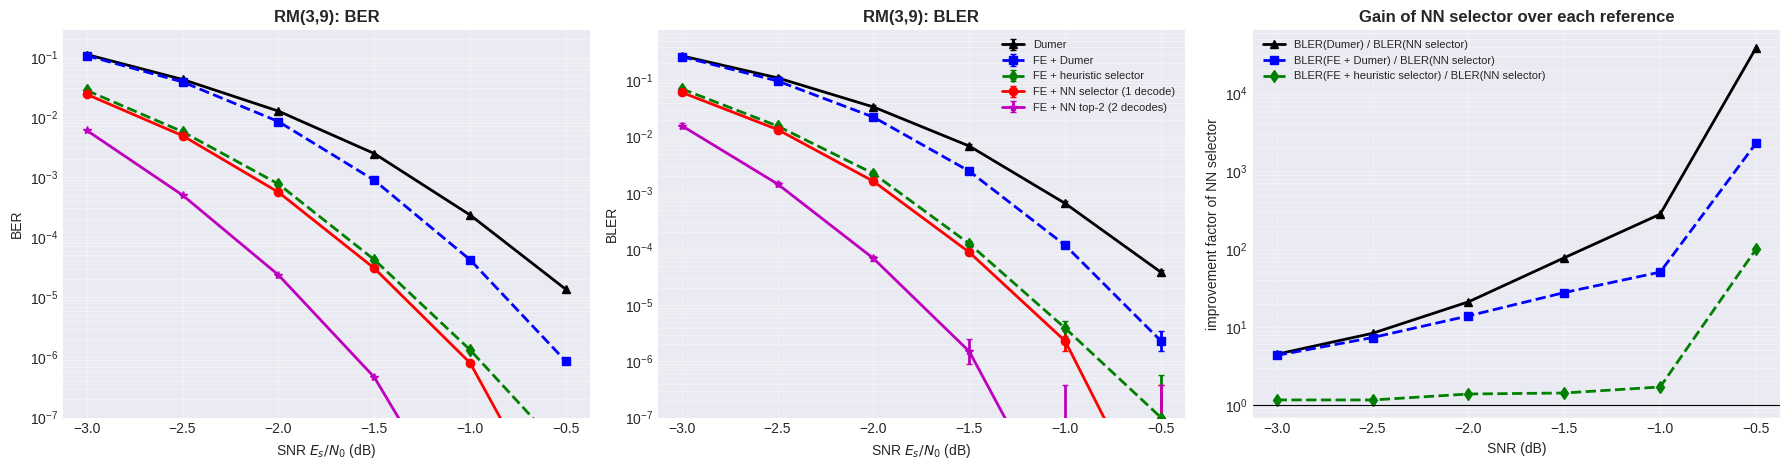

✓ Figures saved to disk (error bars: 95% Wilson interval; points with few block errors are statistically weak)


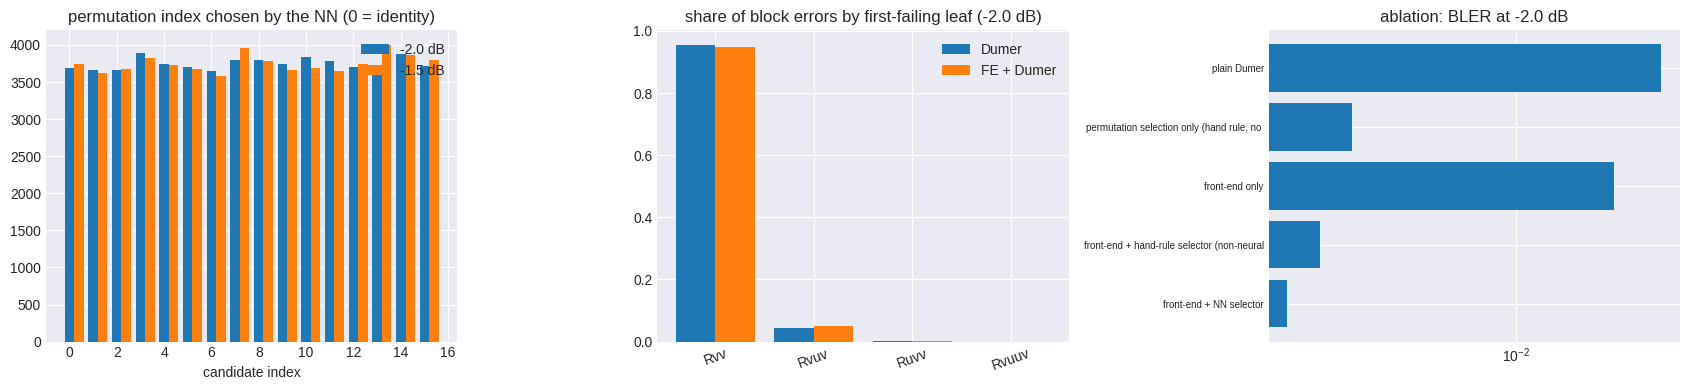

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
styles = {'Dumer': 'k^-', 'FE + Dumer': 'bs--', 'FE + heuristic selector': 'g d--',
          'FE + NN selector (1 decode)': 'ro-', 'FE + NN top-2 (2 decodes)': 'm*-', 'oracle (P decodes)': 'c:'}
for n in NAMES:
    ax = axes[1]; bl = np.array(wf[n]['bler']); w_ = np.array(wf[n]['words']); e_ = np.array(wf[n]['blk_err'])
    ci = np.array([wilson(int(a_), int(b_)) for a_, b_ in zip(e_, w_)])
    ax.errorbar(wf[n]['snr'], np.maximum(bl, 1e-9), yerr=[np.maximum(bl - ci[:, 0], 0), np.maximum(ci[:, 1] - bl, 0)],
                fmt=styles[n].replace(' ', ''), label=n, linewidth=2, markersize=6, capsize=2)
    ax.set_yscale('log')
    axes[0].semilogy(wf[n]['snr'], np.maximum(wf[n]['ber'], 1e-9), styles[n].replace(' ', ''), label=n, linewidth=2, markersize=6)
for ax, t in zip(axes[:2], ['BER', 'BLER']):
    ax.set_xlabel('SNR $E_s/N_0$ (dB)'); ax.set_ylabel(t); ax.set_ylim(bottom=1e-7)
    ax.set_title(f'RM({R},{M}): {t}', fontweight='bold'); ax.grid(True, which='both', alpha=0.3)
axes[1].legend(fontsize=8)
nn1 = np.maximum(np.array(wf['FE + NN selector (1 decode)']['bler']), 1e-9)
for ref, st in [('Dumer', 'k^-'), ('FE + Dumer', 'bs--'), ('FE + heuristic selector', 'gd--')]:
    axes[2].semilogy(wf[ref]['snr'], np.array(wf[ref]['bler']) / nn1, st, linewidth=2, label=f'BLER({ref}) / BLER(NN selector)')
axes[2].axhline(1, color='k', lw=0.8); axes[2].set_xlabel('SNR (dB)'); axes[2].set_ylabel('improvement factor of NN selector')
axes[2].set_title('Gain of NN selector over each reference', fontweight='bold'); axes[2].legend(fontsize=8)
axes[2].grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()
fig.savefig(RESULTS_DIR / "results_visualization.png", dpi=PLOT_DPI, bbox_inches='tight')
print("✓ Figures saved to disk (error bars: 95% Wilson interval; points with few block errors are statistically weak)")

if analysis_json.get(f'{ANALYSIS_SNRS[0]:+.2f}dB'):
    fig2, ax2 = plt.subplots(1, 3, figsize=(17, 4))
    for aj, snr_ in zip([analysis_json[f'{s_:+.2f}dB'] for s_ in ANALYSIS_SNRS], ANALYSIS_SNRS):
        ax2[0].bar(np.arange(P_PERMS) + (0.4 if snr_ == ANALYSIS_SNRS[-1] else 0), aj['perm_hist'], width=0.4, label=f'{snr_:+.1f} dB')
    ax2[0].set_title('permutation index chosen by the NN (0 = identity)'); ax2[0].set_xlabel('candidate index'); ax2[0].legend()
    aj = analysis_json[f'{ANALYSIS_SNRS[0]:+.2f}dB']
    for k_, m_ in enumerate(['Dumer', 'FE + Dumer']):
        ff = np.array(aj['first_leaf'][m_]); top = np.argsort(-ff)[:4]
        ax2[1].bar(np.arange(4) + 0.4 * k_, ff[top] / max(ff.sum(), 1), width=0.4, label=m_)
        ax2[1].set_xticks(np.arange(4) + 0.2); ax2[1].set_xticklabels([aj['leaves'][i] for i in np.argsort(-np.array(aj['first_leaf']['Dumer']))[:4]], rotation=20)
    ax2[1].set_title(f'share of block errors by first-failing leaf ({ANALYSIS_SNRS[0]:+.1f} dB)'); ax2[1].legend()
    ab = aj['ablation']; names_ = list(ab); ax2[2].barh(range(len(ab)), [max(v_, 0.5) / aj['frames'] for v_ in ab.values()])
    ax2[2].set_yticks(range(len(ab))); ax2[2].set_yticklabels([n_[:42] for n_ in names_], fontsize=7); ax2[2].set_xscale('log')
    ax2[2].set_title(f'ablation: BLER at {ANALYSIS_SNRS[0]:+.1f} dB'); ax2[2].invert_yaxis()
    plt.tight_layout(); plt.show()
    fig2.savefig(RESULTS_DIR / "analysis_figures.png", dpi=PLOT_DPI, bbox_inches='tight')

## Save results (.mat, .txt, config.json)

In [12]:
if MODE == "compute_and_save":
    metrics_dict = {'R': R, 'M': M, 'seed': SEED, 'P_perms': P_PERMS, 'use_frontend': int(USE_FRONTEND),
                    'hist_epoch': np.array(history['epoch']), 'hist_train_loss': np.array(history['train_loss']),
                    'hist_val_acc': np.array(history['val_acc'])}
    for n in NAMES:
        for k_, v_ in wf[n].items():
            metrics_dict[f"{SHORT[n]}_{k_}"] = np.array(v_)
    lines = [f"{'=' * 70}\nEXPERIMENT RESULTS SUMMARY\n{'=' * 70}\n",
             f"Code: RM({R},{M})  k={D.k} n={D.n} rate={D.k / D.n:.3f}",
             f"Front-end: {'ON' if USE_FRONTEND else 'OFF'} (dv={DV}, T={T_ROUNDS}, alpha={ALPHA_INIT}); candidates P={P_PERMS}",
             f"Selector training: {TRAIN_FRAMES} frames at SNRs {TRAIN_SNRS}, {EPOCHS} epochs, best val selection accuracy {best_acc:.3f}",
             f"Evaluation: >= {MIN_BLOCK_ERRORS} block errors per point (cap {MAX_WORDS} words); BLER/BER (block errors)\n",
             f"{'SNR':>6} | " + " | ".join(f"{SHORT[n]:>22}" for n in NAMES)]
    for i, snr in enumerate(EVAL_SNRS):
        lines.append(f"{snr:6.2f} | " + " | ".join(
            f"{wf[n]['bler'][i]:.2e}/{wf[n]['ber'][i]:.1e} ({int(wf[n]['blk_err'][i]):4d})" for n in NAMES))
    lines += ["", "dumer=plain Dumer; fe=classical front-end + Dumer; heur=hand rule selects the permutation (max first-leaf correlation);",
              "nn1=neural selector then ONE full Dumer decode; nn2=neural top-2, both decoded, better by likelihood.",
              "Points with fewer than MIN_BLOCK_ERRORS errors hit the word cap and are statistically weak."]
    save_results(metrics_dict, "\n".join(lines), RESULTS_DIR)
    with open(RESULTS_DIR / "analysis_summary.txt", 'w') as f_:
        f_.write("\n".join(analysis_lines))
    with open(RESULTS_DIR / "analysis.json", 'w') as f_:
        json.dump(analysis_json, f_, indent=1)
    print(f"✓ Analysis saved: {RESULTS_DIR / 'analysis_summary.txt'} (+ analysis.json)")
    log_all_config(RESULTS_BASE_DIR)
    print("\n" + "=" * 70 + "\n✓ ALL RESULTS SAVED SUCCESSFULLY!\n" + "=" * 70)
    print(f"Results Location: {RESULTS_BASE_DIR.absolute()}")
else:
    print("analyze_only: nothing to save")

✓ Metrics saved (MATLAB .mat): ResultsAndWeights/HiKO_PermSel_r3_m9_fe1_dv128_T2_a040_P16_frames1000000_ep120_seed42_20261011_185517/results_data/results_metrics.mat
✓ Results saved (text format): ResultsAndWeights/HiKO_PermSel_r3_m9_fe1_dv128_T2_a040_P16_frames1000000_ep120_seed42_20261011_185517/results_data/results_summary.txt
✓ Analysis saved: ResultsAndWeights/HiKO_PermSel_r3_m9_fe1_dv128_T2_a040_P16_frames1000000_ep120_seed42_20261011_185517/results_data/analysis_summary.txt (+ analysis.json)
✓ Configuration saved: ResultsAndWeights/HiKO_PermSel_r3_m9_fe1_dv128_T2_a040_P16_frames1000000_ep120_seed42_20261011_185517/config.json

✓ ALL RESULTS SAVED SUCCESSFULLY!
Results Location: /DATA/shubham19/Documents/python_directory/higher_rate_kocodes/General-Rate-KO-Codes/selector_notebooks/ResultsAndWeights/HiKO_PermSel_r3_m9_fe1_dv128_T2_a040_P16_frames1000000_ep120_seed42_20261011_185517
